## **Analysis of NYC Flight 2013 Dataset using Python (Pandas, Numpy, Seaborn, Matplotlib)**

## PART I

**Dataset:** `nycflights13` — flights data that departed NYC (EWR, JFK, LGA) in 2013, plus
supporting tables for airlines, airports, planes and weather.

**Goal:** work through this data - start with data quality check, data cleaning and feature engineering where necessary, then take on single-table questions, checking at each step whether a pattern is real or just noise before calling it a finding.

**Tables:** `flights`, `airlines`, `airports`, `planes`, `weather`.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from nycflights13 import flights, airlines, airports, planes, weather
#Minidataset #1 - flights
df = flights.copy()
print("Flights shape:", df.shape)
display(df.head())

#Minidataset #2 - airlines
df1=airlines.copy()
print("Airlines.shape:", df1.shape)
display(df1.head())

#Minidataset #3 - airports
df2=airports.copy()
print("Airports shape", df2.shape)
display(df2.head())

#Minidataset #4 - planes
df3=planes.copy()
print("Planes shape", df3.shape)
display(df3.head())

#Minidataset #5 - weather
df4=weather.copy()
print("Weather shape", df4.shape)
display(df4.head())


C:\Users\anupr\AppData\Roaming\Python\Python314\site-packages\nycflights13\__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename as _rf


Flights shape: (336776, 19)


,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01T10:00:00Z
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01T10:00:00Z
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01T10:00:00Z
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01T10:00:00Z
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01T11:00:00Z


Airlines.shape: (16, 2)


,carrier,name
0,9E,Endeavor Air Inc.
1,AA,American Airlines Inc.
2,AS,Alaska Airlines Inc.
3,B6,JetBlue Airways
4,DL,Delta Air Lines Inc.


Airports shape (1458, 8)


,faa,name,lat,lon,alt,tz,dst,tzone
0,04G,Lansdowne Airport,41.130472,-80.619583,1044,-5,A,America/New_York
1,06A,Moton Field Municipal Airport,32.460572,-85.680028,264,-6,A,America/Chicago
2,06C,Schaumburg Regional,41.989341,-88.101243,801,-6,A,America/Chicago
3,06N,Randall Airport,41.431912,-74.391561,523,-5,A,America/New_York
4,09J,Jekyll Island Airport,31.074472,-81.427778,11,-5,A,America/New_York


Planes shape (3322, 9)


,tailnum,year,type,manufacturer,model,engines,seats,speed,engine
0,N10156,2004.0,Fixed wing multi engine,EMBRAER,EMB-145XR,2,55,NaN,Turbo-fan
1,N102UW,1998.0,Fixed wing multi engine,AIRBUS INDUSTRIE,A320-214,2,182,NaN,Turbo-fan
2,N103US,1999.0,Fixed wing multi engine,AIRBUS INDUSTRIE,A320-214,2,182,NaN,Turbo-fan
3,N104UW,1999.0,Fixed wing multi engine,AIRBUS INDUSTRIE,A320-214,2,182,NaN,Turbo-fan
4,N10575,2002.0,Fixed wing multi engine,EMBRAER,EMB-145LR,2,55,NaN,Turbo-fan


Weather shape (26115, 15)


,origin,year,month,day,hour,temp,dewp,humid,wind_dir,wind_speed,wind_gust,precip,pressure,visib,time_hour
0,EWR,2013,1,1,1,39.02,26.06,59.37,270.0,10.35702,NaN,0.0,1012.0,10.0,2013-01-01T06:00:00Z
1,EWR,2013,1,1,2,39.02,26.96,61.63,250.0,8.05546,NaN,0.0,1012.3,10.0,2013-01-01T07:00:00Z
2,EWR,2013,1,1,3,39.02,28.04,64.43,240.0,11.50780,NaN,0.0,1012.5,10.0,2013-01-01T08:00:00Z
3,EWR,2013,1,1,4,39.92,28.04,62.21,250.0,12.65858,NaN,0.0,1012.2,10.0,2013-01-01T09:00:00Z
4,EWR,2013,1,1,5,39.02,28.04,64.43,260.0,12.65858,NaN,0.0,1011.9,10.0,2013-01-01T10:00:00Z


In [2]:
df.info() #flights
df1.info() #airlines
df2.info() #airports
df3.info() #plane
df4.info() #weather

<class 'pandas.DataFrame'>
RangeIndex: 336776 entries, 0 to 336775
Data columns (total 19 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   year            336776 non-null  int64  
 1   month           336776 non-null  int64  
 2   day             336776 non-null  int64  
 3   dep_time        328521 non-null  float64
 4   sched_dep_time  336776 non-null  int64  
 5   dep_delay       328521 non-null  float64
 6   arr_time        328063 non-null  float64
 7   sched_arr_time  336776 non-null  int64  
 8   arr_delay       327346 non-null  float64
 9   carrier         336776 non-null  str    
 10  flight          336776 non-null  int64  
 11  tailnum         334264 non-null  str    
 12  origin          336776 non-null  str    
 13  dest            336776 non-null  str    
 14  air_time        327346 non-null  float64
 15  distance        336776 non-null  int64  
 16  hour            336776 non-null  int64  
 17  minute          33677

## 1. Flights (df)

#### **1.1** Quick overview/description of Flights data

In [3]:
df.describe(include="all").T #flights

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
year,336776.0,NaN,NaN,NaN,2013.0,0.0,2013.0,2013.0,2013.0,2013.0,2013.0
month,336776.0,NaN,NaN,NaN,6.54851,3.414457,1.0,4.0,7.0,10.0,12.0
day,336776.0,NaN,NaN,NaN,15.710787,8.768607,1.0,8.0,16.0,23.0,31.0
dep_time,328521.0,NaN,NaN,NaN,1349.109947,488.281791,1.0,907.0,1401.0,1744.0,2400.0
sched_dep_time,336776.0,NaN,NaN,NaN,1344.25484,467.335756,106.0,906.0,1359.0,1729.0,2359.0
dep_delay,328521.0,NaN,NaN,NaN,12.63907,40.210061,-43.0,-5.0,-2.0,11.0,1301.0
arr_time,328063.0,NaN,NaN,NaN,1502.054999,533.264132,1.0,1104.0,1535.0,1940.0,2400.0
sched_arr_time,336776.0,NaN,NaN,NaN,1536.38022,497.457142,1.0,1124.0,1556.0,1945.0,2359.0
arr_delay,327346.0,NaN,NaN,NaN,6.895377,44.633292,-86.0,-17.0,-5.0,14.0,1272.0
carrier,336776,16,UA,58665,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Overall scope

In [4]:
print("Date range: all of", df["year"].unique()) #unique - returns values in form of an array
print("Origin airports:", sorted(df["origin"].unique()))
print("Unique destinations:", df["dest"].nunique()) # nunique returns count - nunique same as len(series.unique())
print("Unique carriers:", df["carrier"].nunique())
print("Total flights:", f"{len(df):,}")

Date range: all of [2013]
Origin airports: ['EWR', 'JFK', 'LGA']
Unique destinations: 105
Unique carriers: 16
Total flights: 336,776


### **1.2** Data Quality check
Before analysis, let's carry out identification of missing data and what could be the reasons behind missing data in this dataset.

In [5]:
#Flights
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().sum()/len(df)*100).round(2)
}).sort_values("missing_count", ascending=False)

missing.head(15)


,missing_count,missing_percentage
arr_delay,9430,2.80
air_time,9430,2.80
arr_time,8713,2.59
dep_time,8255,2.45
dep_delay,8255,2.45
tailnum,2512,0.75
year,0,0.00
day,0,0.00
month,0,0.00
sched_dep_time,0,0.00


### Q1. Which values are missing ?

`dep_time`, `dep_delay`, `arr_time`, `arr_delay`, `air_time` and `tailnum` values are missing

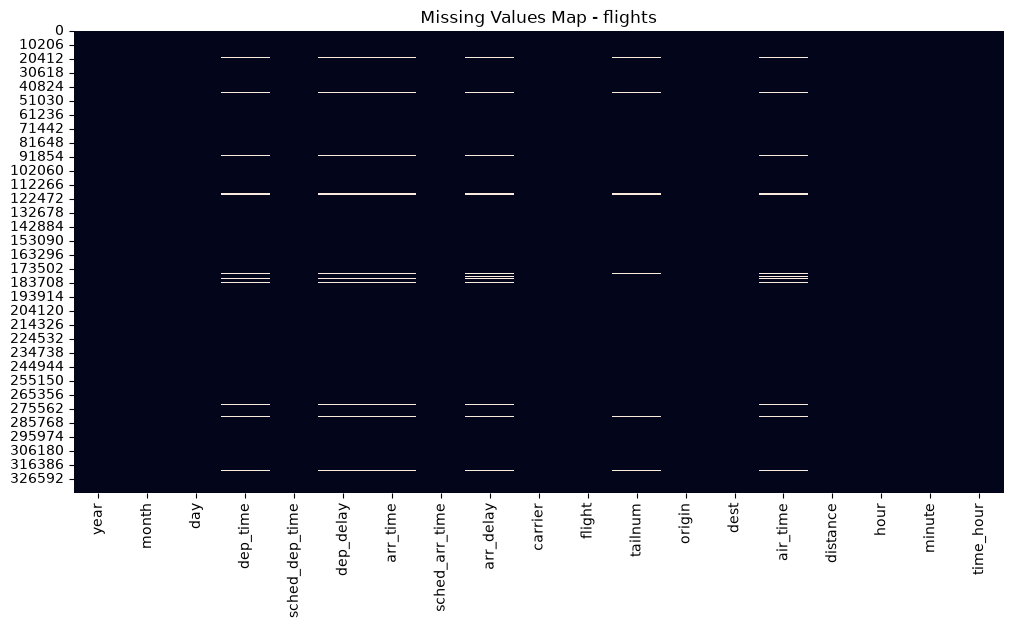

In [6]:
plt.figure(figsize=(12,6))
sns.heatmap(df.isna(), cbar=False)
plt.title("Missing Values Map - flights")
plt.show()

### Q2. Are there flights with no departure time (cancelled)  ?

In [7]:
n_cancelled = df["dep_time"].isnull().sum()
print(f"\nFlights with no dep_time (cancelled): {n_cancelled} "
      f"({n_cancelled/len(flights)*100:.2f}% of all flights)")


Flights with no dep_time (cancelled): 8255 (2.45% of all flights)


**Takeaway:** 
8,255 flights have no departure data, which means they were cancelled. A further ~1,175 flights departed but have no arrival delay or air time recorded, most likely diversions or missing arrival records.

`tailnum` is missing for a smaller set (2,512 rows), most likely older/decommissioned aircraft not in FAA records. 

Best to keep the cancelled flights data (unimputed)  for volume analysis but can be excluded as deemed fit later in future.

### Q3. Are there any duplicates  ?

In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


### **1.3** Feature Engineering

In [9]:
df_clean= df.copy()

#convert main datetime-related columns safely
date_cols=["time_hour"]
for col in date_cols:
    df_clean[col] = pd.to_datetime(df_clean[col], errors="coerce")

#replace any empty fields with NaN (not a number)
df_clean["tailnum"]=df_clean["tailnum"].replace("",np.nan)

#remove exact duplicates
df_clean = df_clean.drop_duplicates().reset_index(drop=True) #reset the column numbers to 1,2,3,...

print("Cleaned Shape:",df_clean.shape)
print(df_clean)


Cleaned Shape: (336776, 19)
        year  month  day  dep_time  sched_dep_time  dep_delay  arr_time  \
0       2013      1    1     517.0             515        2.0     830.0   
1       2013      1    1     533.0             529        4.0     850.0   
2       2013      1    1     542.0             540        2.0     923.0   
3       2013      1    1     544.0             545       -1.0    1004.0   
4       2013      1    1     554.0             600       -6.0     812.0   
...      ...    ...  ...       ...             ...        ...       ...   
336771  2013      9   30       NaN            1455        NaN       NaN   
336772  2013      9   30       NaN            2200        NaN       NaN   
336773  2013      9   30       NaN            1210        NaN       NaN   
336774  2013      9   30       NaN            1159        NaN       NaN   
336775  2013      9   30       NaN             840        NaN       NaN   

        sched_arr_time  arr_delay carrier  flight tailnum origin dest  

### Q4. Does flight cancellation rate vary by month?

In [10]:
df_clean["is_cancelled"] = df_clean["dep_time"].isnull() #created a new column here storing boolean values
print((df_clean.groupby("month")["is_cancelled"].mean() * 100).round(2))

month
1     1.93
2     5.05
3     2.99
4     2.36
5     1.96
6     3.57
7     3.19
8     1.66
9     1.64
10    0.82
11    0.85
12    3.64
Name: is_cancelled, dtype: float64


#### Response: 
Yes, substantially - February has the highest cancellation rate (5.05%).
February's winter-storm is the likely reason.

### Q5. Which day of the week has the highest average departure delay?

In [11]:
df_clean["date"] = pd.to_datetime(df_clean[["year", "month", "day"]])
df_clean["day_of_week"] = df_clean["date"].dt.day_name()

print(df_clean.groupby("day_of_week")["dep_delay"].mean().sort_values(ascending=False).round(2))

day_of_week
Thursday     16.15
Monday       14.78
Friday       14.70
Wednesday    11.80
Sunday       11.59
Tuesday      10.63
Saturday      7.65
Name: dep_delay, dtype: float64


#### Response
Thursday (16.15 min avg) and Monday (14.78 min) are worst; Saturday is by far the
best (7.65 min).

### Q6. Is there a meaningful weekday vs. weekend difference in departure delay?

In [12]:
df_clean["is_weekend"] = df_clean["day_of_week"].isin(["Saturday", "Sunday"])

print(df_clean.groupby("is_weekend")["dep_delay"].mean().round(2))

is_weekend
False    13.61
True      9.80
Name: dep_delay, dtype: float64


#### Response 
Yes - weekday flights average 13.61 min delay vs. 9.80 min on weekend.

### Q7. How is flights data correlated?

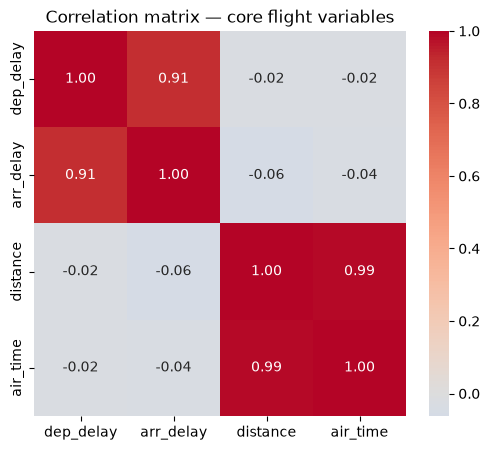

In [13]:
numeric_cols = ["dep_delay", "arr_delay", "distance", "air_time"]
corr_matrix = flights[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, ax=ax, fmt=".2f")
ax.set_title("Correlation matrix — core flight variables")
plt.show()

**Takeaway:** 
`dep_delay` and `arr_delay` are very strongly correlated (0.91-ish) - since a late departure is the single biggest driver of a late arrival. 
`Distance` and `air_time` are almost perfectly correlated (longer routes take longer), and neither has any meaningful relationship with
`delay` - trip length itself isn't a delay driver in this dataset.

## 2. Airlines Data Cleaning, Feature Engg and basic EDA (df1)

#### **2.1** Quick overview/description of Airlines data

In [14]:
df1.describe(include="all").T #airlines

,count,unique,top,freq
carrier,16,16,9E,1
name,16,16,Endeavor Air Inc.,1


In [15]:
print(df1.head(5))

  carrier                    name
0      9E       Endeavor Air Inc.
1      AA  American Airlines Inc.
2      AS    Alaska Airlines Inc.
3      B6         JetBlue Airways
4      DL    Delta Air Lines Inc.


### **2.2** Data Quality check
Before analysis, let's carry out identification of missing data and what could be the reasons behind missing data in this dataset.

In [16]:
#Airlines
missing = pd.DataFrame({
    "missing_count": df1.isna().sum(),
    "missing_percentage": (df1.isna().sum()/len(df1)*100).round(2)
}).sort_values("missing_count", ascending=False)

missing.head(15)

,missing_count,missing_percentage
carrier,0,0.0
name,0,0.0


### Q1. Which values are missing ?

#### Response:
No missing values

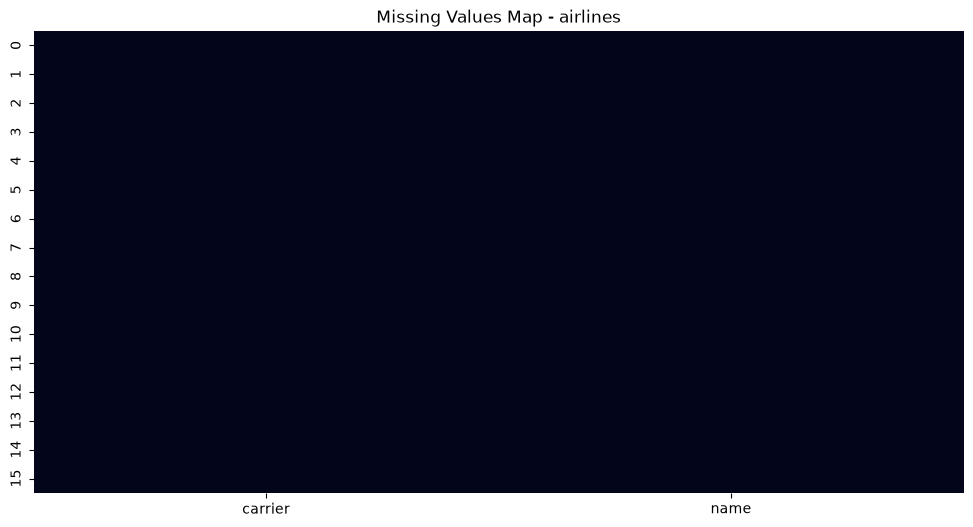

In [17]:
plt.figure(figsize=(12,6))
sns.heatmap(df1.isna(), cbar=False)
plt.title("Missing Values Map - airlines")
plt.show()

In [18]:
print("Duplicate rows:", df1.duplicated().sum())

Duplicate rows: 0


### Q2. Are there any missing values anywhere in this table?

In [19]:
print(df1[["carrier", "name"]].isnull().sum())

carrier    0
name       0
dtype: int64


#### Response 
Table is clean — no missing values, no duplicates

### Q3. Sorted alphabetically by full name, which airline comes first and last?

In [20]:
sorted_names = df1.sort_values("name")

print("First:", sorted_names.iloc[0]["name"])
print("Last:", sorted_names.iloc[-1]["name"])

First: AirTran Airways Corporation
Last: Virgin America


### Q4. How many distinct airlines are in the reference table?

In [21]:
print(len(df1))

16


## Q5. How can we analyze delays by carriers?

In [74]:
carrier_stats = (
    df.groupby("carrier")
    .agg(
        n_flights=("flight", "count"),
        avg_dep_delay=("dep_delay", "mean"),
        avg_arr_delay=("arr_delay", "mean"),
        pct_delayed_15min=("dep_delay", lambda x: (x > 15).mean() * 100),
    )
    .merge(df1, on="carrier")
    .set_index("name")
    .sort_values("avg_arr_delay", ascending=False)
    .round(2)
)

print(carrier_stats)

                            carrier  n_flights  avg_dep_delay  avg_arr_delay  \
name                                                                           
Frontier Airlines Inc.           F9        685          20.22          21.92   
AirTran Airways Corporation      FL       3260          18.73          20.12   
ExpressJet Airlines Inc.         EV      54173          19.96          15.80   
Mesa Airlines Inc.               YV        601          19.00          15.56   
SkyWest Airlines Inc.            OO         32          12.59          11.93   
Envoy Air                        MQ      26397          10.55          10.77   
Southwest Airlines Co.           WN      12275          17.71           9.65   
JetBlue Airways                  B6      54635          13.02           9.46   
Endeavor Air Inc.                9E      18460          16.73           7.38   
United Air Lines Inc.            UA      58665          12.11           3.56   
US Airways Inc.                  US     

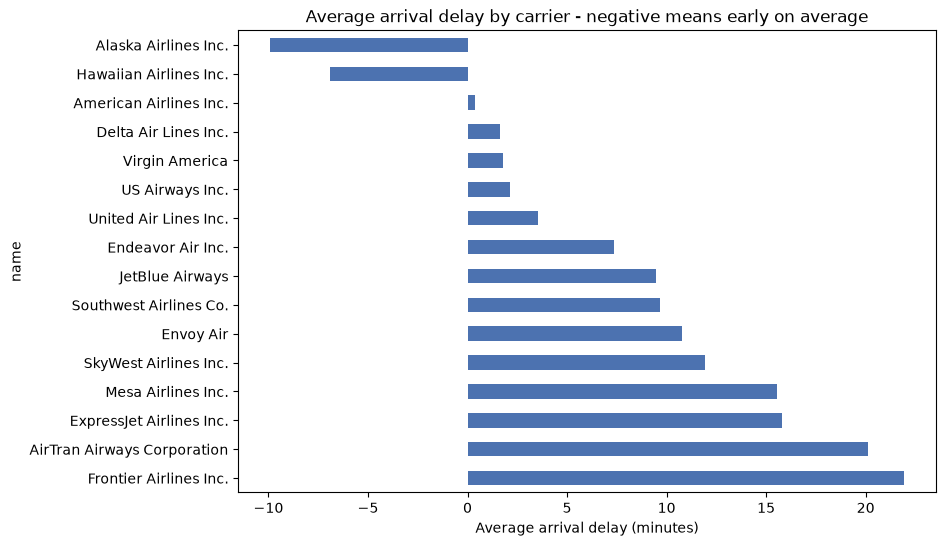

In [75]:
fig, ax = plt.subplots(figsize=(9, 6))
carrier_stats["avg_arr_delay"].plot(kind="barh", ax=ax, color="#4C72B0")  # syntax (select column -> sort -> plot -- if need to sort)
ax.set_xlabel("Average arrival delay (minutes)")
ax.set_title("Average arrival delay by carrier - negative means early on average")
plt.show()

**Key Takeaway:** 

`Frontier (F9) and AirTran (FL)` have the worst average arrival delays (~20-22
min)
`Alaska (AS) and Hawaiian (HA)` planes land early on average.

## 3. Airports Data Cleaning, Feature Engg and basic EDA(df2)

#### **3.1** Quick overview/description of Airport data

In [24]:
df2.describe(include="all").T #airports

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
faa,1458,1458,04G,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,1458,1440,Municipal Airport,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lat,1458.0,NaN,NaN,NaN,41.648008,10.449509,19.721375,34.257539,40.087722,45.06715,72.270833
lon,1458.0,NaN,NaN,NaN,-103.392289,29.843118,-176.646,-119.185652,-94.661854,-82.516717,174.11362
alt,1458.0,NaN,NaN,NaN,1001.415638,1523.626105,-54.0,70.25,473.0,1062.5,9078.0
tz,1458.0,NaN,NaN,NaN,-6.518519,1.623016,-10.0,-8.0,-6.0,-5.0,8.0
dst,1458,3,A,1388,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tzone,1455,9,America/New_York,519,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
print(df2.head(15))

    faa                                  name        lat         lon   alt  \
0   04G                     Lansdowne Airport  41.130472  -80.619583  1044   
1   06A         Moton Field Municipal Airport  32.460572  -85.680028   264   
2   06C                   Schaumburg Regional  41.989341  -88.101243   801   
3   06N                       Randall Airport  41.431912  -74.391561   523   
4   09J                 Jekyll Island Airport  31.074472  -81.427778    11   
5   0A9        Elizabethton Municipal Airport  36.371222  -82.173417  1593   
6   0G6               Williams County Airport  41.467306  -84.506778   730   
7   0G7         Finger Lakes Regional Airport  42.883565  -76.781232   492   
8   0P2          Shoestring Aviation Airfield  39.794824  -76.647191  1000   
9   0S9                 Jefferson County Intl  48.053809 -122.810644   108   
10  0W3                Harford County Airport  39.566838  -76.202403   409   
11  10C                    Galt Field Airport  42.402889  -88.37

### **3.2** Data Quality check
Before analysis, let's carry out identification of missing data and what could be the reasons behind missing data in this dataset.

In [4]:
#Airports
missing = pd.DataFrame({
    "missing_count": df2.isna().sum(),
    "missing_percentage": (df2.isna().sum()/len(df2)*100).round(2)
}).sort_values("missing_count", ascending=False)

missing.head(15)

,missing_count,missing_percentage
tzone,3,0.21
faa,0,0.00
lat,0,0.00
name,0,0.00
lon,0,0.00
alt,0,0.00
tz,0,0.00
dst,0,0.00


### Q1. Which values are missing ? How do we handle this?

##### **Response:**
**1**
`tzone` is the only identified column with missing values.
Also, reflected in the Missing Values map below
**2**
Since `tzone` values are only impacting Airports and Flights tables - and per our assessment below the missing tzone fields are not impacting either flights/airports data. **OK to retain the rows with missing t_zone**  

In [27]:
missing_tz = df2[df2["tzone"].isnull()]
print(missing_tz)
print(missing_tz["faa"])

      faa                                  name        lat         lon  alt  \
417   EEN               Dillant Hopkins Airport  72.270833   42.898333  149   
815   LRO  Mount Pleasant Regional-Faison Field  32.538700  -79.469700   12   
1434  YAK                               Yakutat  59.301200 -139.393700   33   

      tz dst tzone  
417   -5   A   NaN  
815   -5   A   NaN  
1434  -9   A   NaN  
417     EEN
815     LRO
1434    YAK
Name: faa, dtype: str


In [28]:
#checking in flights table whether to drop/retain rows with missing tzone values

print(df["dest"].isin(missing_tz["faa"]).sum(), "flights to these destinations") 
print(df["origin"].isin(missing_tz["faa"]).sum(), "flights from these origins") 

0 flights to these destinations
0 flights from these origins


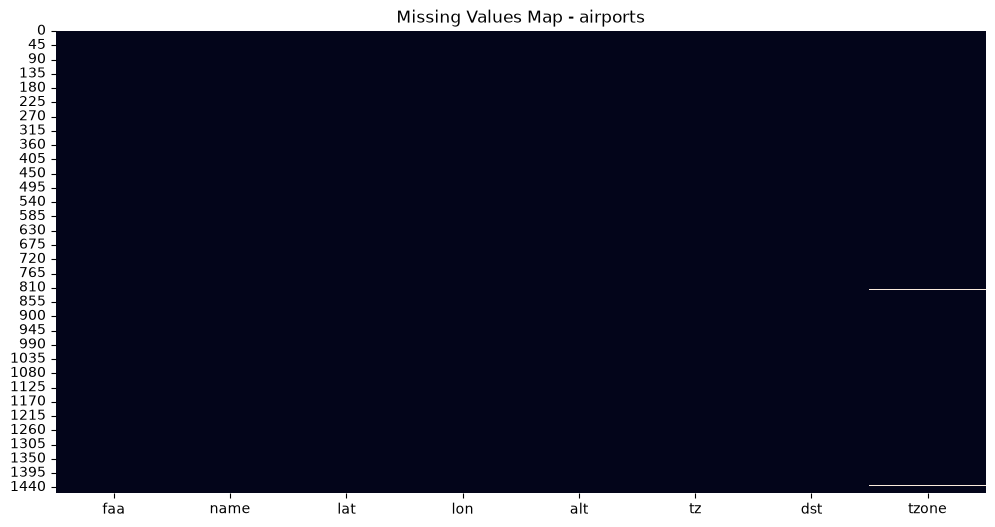

In [29]:
plt.figure(figsize=(12,6))
sns.heatmap(df2.isna(), cbar=False)
plt.title("Missing Values Map - airports")
plt.show()

### Q2. Are there any duplicates ?

In [30]:
print("Duplicate rows:", df2.duplicated().sum())

Duplicate rows: 0


### Q3. How many distinct named time zone regions (`tzone`) are represented ?

In [31]:
print(df2["tzone"].value_counts())

tzone
America/New_York       519
America/Chicago        342
America/Anchorage      239
America/Los_Angeles    176
America/Denver         119
America/Phoenix         38
Pacific/Honolulu        18
America/Vancouver        2
Asia/Chongqing           2
Name: count, dtype: int64


### Q4. How many airports (distinct named FAA codes) exist in this dataset ?

In [32]:
df2["faa"].nunique()

1458

### Q5. Which airport is northernmost and southernmost?

In [3]:
# EEN (Dillant Hopkins, Keene NH) has bad coordinates in the source data: lat/lon look swapped
# (lat 72.27, lon +42.90 instead of about 42.90, -72.27), so exclude it before ranking by latitude.
valid = df2[df2["faa"] != "EEN"]
print("Northernmost:", valid.loc[valid["lat"].idxmax(), ["faa","name","lat"]].to_dict())
print("Southernmost:", valid.loc[valid["lat"].idxmin(), ["faa","name","lat"]].to_dict())

Northernmost: {'faa': 'BRW', 'name': 'Wiley Post Will Rogers Mem', 'lat': 71.285446}
Southernmost: {'faa': 'ITO', 'name': 'Hilo Intl', 'lat': 19.721375}


The raw data lists Dillant Hopkins (EEN) as northernmost at lat 72.27, but this is a data error. EEN is in Keene, NH (about 42.9°N, 72.3°W), and its latitude and longitude appear swapped in the source. After excluding it, the northernmost airport is Wiley Post Will Rogers Memorial (BRW, Alaska) at 71.29°N, and the southernmost is Hilo Intl (ITO, Hawaii) at 19.72°N.

### Q6. Which airport is easternmost and westernmost?

In [77]:
print("Westernmost:",df2.loc[df2["lon"].idxmin(),["faa","name","lon"]].to_dict()) #idxmin/idxmax returns the full row as compared to min/max which only reutrns row position
print("Easternmost:",df2.loc[df2["lon"].idxmax(),["faa","name","lon"]].to_dict()) 

Westernmost: {'faa': 'ADK', 'name': 'Adak Airport', 'lon': -176.646}
Easternmost: {'faa': 'SYA', 'name': 'Eareckson As', 'lon': 174.11362}


Note: SYA (Shemya, Aleutians) is the highest longitude because the Aleutian Islands cross the 180° line. Two other airports (DVT and MYF) also appear to have longitude sign errors in the source data, so “easternmost” by raw longitude isn’t meaningful for this dataset.

### Q7. What proportion of airports are outside the America/New_York time zone?

In [35]:
not_nyc=(df2["tzone"]!="America/New_York").sum()
print(round(not_nyc/len(df2)*100,1),"%")

64.4 %


### Q8. How many airports qualify as "high altitude" (>1,000 ft)?

In [36]:
print((df2["alt"]>1000).sum(), "of", len(df2))

391 of 1458


## 4. Planes Data Cleaning, Feature Engg and basic EDA(df3)

#### **4.1** Quick overview/description of Planes data

In [37]:
df3.describe(include="all").T #planes

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
tailnum,3322,3322,N10156,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,3252.0,NaN,NaN,NaN,2000.48401,7.193425,1956.0,1997.0,2001.0,2005.0,2013.0
type,3322,3,Fixed wing multi engine,3292,NaN,NaN,NaN,NaN,NaN,NaN,NaN
manufacturer,3322,35,BOEING,1630,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,3322,127,737-7H4,361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engines,3322.0,NaN,NaN,NaN,1.995184,0.117593,1.0,2.0,2.0,2.0,4.0
seats,3322.0,NaN,NaN,NaN,154.316376,73.654974,2.0,140.0,149.0,182.0,450.0
speed,23.0,NaN,NaN,NaN,236.782609,149.759794,90.0,107.5,162.0,432.0,432.0
engine,3322,6,Turbo-fan,2750,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### **4.2** Data Quality check
Before analysis, let's carry out identification of missing data and what could be the reasons behind missing data in this dataset.

In [38]:
#Planes
missing = pd.DataFrame({
    "missing_count": df3.isna().sum(),
    "missing_percentage": (df3.isna().sum()/len(df3)*100).round(2)
}).sort_values("missing_count", ascending=False)

missing.head(15)

,missing_count,missing_percentage
speed,3299,99.31
year,70,2.11
tailnum,0,0.00
manufacturer,0,0.00
type,0,0.00
model,0,0.00
engines,0,0.00
seats,0,0.00
engine,0,0.00


### Q1. Which values are missing ? How do we handle it?

#### Response: 
**1**
`year` (manufacture year) is missing for 70 aircraft (2.1%) and `speed` is
missing for 99.3% of the fleet. 

**2**
`speed` column will need to be dropped altogether
`year` column -  could be missing data specifically for single engine aircraft. These 70 rows aren't "bad data," they're aircraft that genuinely don't have a manufacturer-issued build year to record because when someone builds one themselves rather than buying from a commercial manufacturer, the FAA registers the builder's name in the manufacturer field instead of a company name, and manufacture year often goes unfiled since there's no factory production record to pull it from. - Retaining as-is.

In [39]:
print(df3["type"].value_counts())

type
Fixed wing multi engine     3292
Fixed wing single engine      25
Rotorcraft                     5
Name: count, dtype: int64


In [40]:
print(df3[df3["type"] == "Fixed wing single engine"])

     tailnum    year                      type           manufacturer  \
424   N201AA  1959.0  Fixed wing single engine                 CESSNA   
686   N315AT     NaN  Fixed wing single engine            JOHN G HESS   
1016  N376AA  1978.0  Fixed wing single engine                  PIPER   
1024  N377AA     NaN  Fixed wing single engine            PAIR MIKE E   
1027  N378AA  1963.0  Fixed wing single engine                 CESSNA   
1105  N394AA  2007.0  Fixed wing single engine     AVIAT AIRCRAFT INC   
1116  N397AA  1985.0  Fixed wing single engine           STEWART MACO   
1190  N425AA  1968.0  Fixed wing single engine                  PIPER   
1433  N508JB  2007.0  Fixed wing single engine     CIRRUS DESIGN CORP   
1469  N517AA     NaN  Fixed wing single engine     HURLEY JAMES LARRY   
1480  N519MQ  1983.0  Fixed wing single engine                 CESSNA   
1484  N520AA  1985.0  Fixed wing single engine           KILDALL GARY   
1489  N521AA     NaN  Fixed wing single engine     

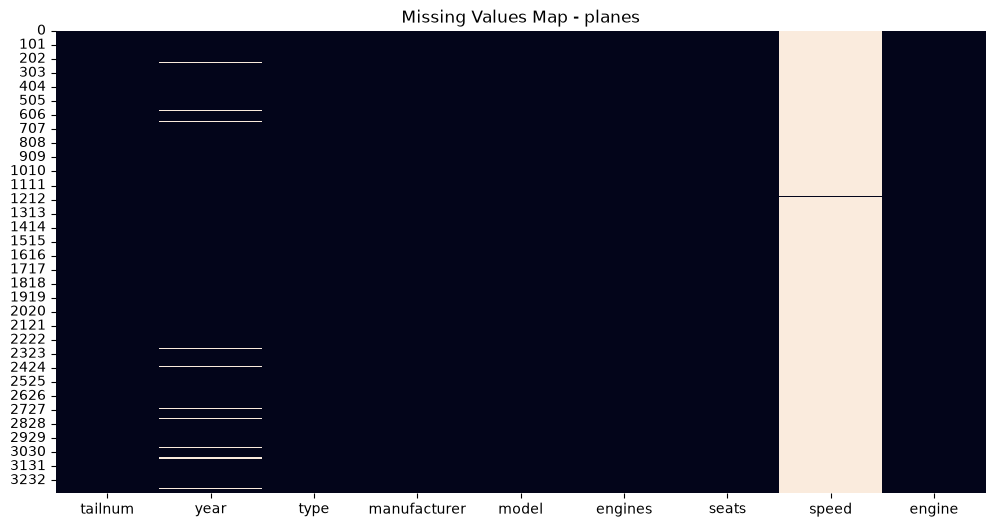

In [41]:
plt.figure(figsize=(12,6))
sns.heatmap(df3.isna(), cbar=False)
plt.title("Missing Values Map - planes")
plt.show()

### Q2. Are there any duplicates ?

In [42]:
print("Duplicate rows:", df3.duplicated().sum())

Duplicate rows: 0


#### Quick snapshot of first 20 rows

In [43]:
display(df3.head(20))

,tailnum,year,type,manufacturer,model,engines,seats,speed,engine
0,N10156,2004.0,Fixed wing multi engine,EMBRAER,EMB-145XR,2,55,NaN,Turbo-fan
1,N102UW,1998.0,Fixed wing multi engine,AIRBUS INDUSTRIE,A320-214,2,182,NaN,Turbo-fan
2,N103US,1999.0,Fixed wing multi engine,AIRBUS INDUSTRIE,A320-214,2,182,NaN,Turbo-fan
3,N104UW,1999.0,Fixed wing multi engine,AIRBUS INDUSTRIE,A320-214,2,182,NaN,Turbo-fan
4,N10575,2002.0,Fixed wing multi engine,EMBRAER,EMB-145LR,2,55,NaN,Turbo-fan
5,N105UW,1999.0,Fixed wing multi engine,AIRBUS INDUSTRIE,A320-214,2,182,NaN,Turbo-fan
6,N107US,1999.0,Fixed wing multi engine,AIRBUS INDUSTRIE,A320-214,2,182,NaN,Turbo-fan
7,N108UW,1999.0,Fixed wing multi engine,AIRBUS INDUSTRIE,A320-214,2,182,NaN,Turbo-fan
8,N109UW,1999.0,Fixed wing multi engine,AIRBUS INDUSTRIE,A320-214,2,182,NaN,Turbo-fan
9,N110UW,1999.0,Fixed wing multi engine,AIRBUS INDUSTRIE,A320-214,2,182,NaN,Turbo-fan


**Dropping the "Speed" column**

In [44]:
aircraft = df3.drop(columns=["speed"])

### Q3. How many distinct aircraft are in the fleet table?

In [45]:
print(len(df3))

3322


### Q4. Which manufacturer has the most aircraft?

In [46]:
print(df3["manufacturer"].value_counts().head(5))

manufacturer
BOEING              1630
AIRBUS INDUSTRIE     400
BOMBARDIER INC       368
AIRBUS               336
EMBRAER              299
Name: count, dtype: int64


### Q5. What share of the fleet is Boeing vs. Airbus (combining Airbus name variants)?

In [47]:
boeing = df3["manufacturer"].str.contains("BOEING").sum()
airbus = df3["manufacturer"].str.contains("AIRBUS").sum()
print(f"Boeing: {boeing} ({boeing/len(df3)*100:.1f}%)")
print(f"Airbus (combined): {airbus} ({airbus/len(df3)*100:.1f}%)")

Boeing: 1630 (49.1%)
Airbus (combined): 736 (22.2%)


### Q6. What's the distribution of `aircraft type`?

In [48]:
print(df3["type"].value_counts())

type
Fixed wing multi engine     3292
Fixed wing single engine      25
Rotorcraft                     5
Name: count, dtype: int64


### Q7. What's the distribution of `engine type`?

In [49]:
print(df3["engine"].value_counts())

engine
Turbo-fan        2750
Turbo-jet         535
Reciprocating      28
Turbo-shaft         5
4 Cycle             2
Turbo-prop          2
Name: count, dtype: int64


### Q8. What are the seat-count summary statistics?

In [50]:
print(df3["seats"].describe().round(2))

count    3322.00
mean      154.32
std        73.65
min         2.00
25%       140.00
50%       149.00
75%       182.00
max       450.00
Name: seats, dtype: float64


### Q9. Which aircraft has the most seats?

In [51]:
print(df3.loc[df3["seats"].idxmax(), ["tailnum", "manufacturer", "model", "seats"]].to_dict())

{'tailnum': 'N670US', 'manufacturer': 'BOEING', 'model': '747-451', 'seats': 450}


### Q10. Which aircraft has the fewest seats?

In [52]:
print(df3.loc[df3["seats"].idxmin(), ["tailnum", "manufacturer", "model", "seats"]].to_dict())

{'tailnum': 'N201AA', 'manufacturer': 'CESSNA', 'model': '150', 'seats': 2}


## 5. Weather Data Cleaning, Feature Engg and basic EDA (df4)

#### **5.1** Quick overview/description of Weather dataset

In [53]:
df4.describe(include="all").T #weather

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
origin,26115,3,JFK,8706,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,26115.0,NaN,NaN,NaN,2013.0,0.0,2013.0,2013.0,2013.0,2013.0,2013.0
month,26115.0,NaN,NaN,NaN,6.503733,3.438328,1.0,4.0,7.0,9.0,12.0
day,26115.0,NaN,NaN,NaN,15.675321,8.762177,1.0,8.0,16.0,23.0,31.0
hour,26115.0,NaN,NaN,NaN,11.490791,6.912423,0.0,6.0,11.0,17.0,23.0
temp,26114.0,NaN,NaN,NaN,55.260392,17.787852,10.94,39.92,55.4,69.98,100.04
dewp,26114.0,NaN,NaN,NaN,41.439985,19.386236,-9.94,26.06,42.08,57.92,78.08
humid,26114.0,NaN,NaN,NaN,62.530059,19.395918,12.74,47.05,61.79,78.79,100.0
wind_dir,25655.0,NaN,NaN,NaN,199.76106,107.306847,0.0,120.0,220.0,290.0,360.0
wind_speed,26111.0,NaN,NaN,NaN,10.517488,8.539253,0.0,6.90468,10.35702,13.80936,1048.36058


### **5.2** Data Quality check
Before analysis, let's carry out identification of missing data and what could be the reasons behind missing data in this dataset.

In [54]:
#Weather
missing = pd.DataFrame({
    "missing_count": df4.isna().sum(),
    "missing_percentage": (df4.isna().sum()/len(df4)*100).round(2)
}).sort_values("missing_count", ascending=False)

missing.head(15)

,missing_count,missing_percentage
wind_gust,20778,79.56
pressure,2729,10.45
wind_dir,460,1.76
wind_speed,4,0.02
dewp,1,0.00
temp,1,0.00
humid,1,0.00
day,0,0.00
hour,0,0.00
year,0,0.00


### Q1. Top THREE missing values?

##### **Response:**
Wind Gust, Pressure and Wind Direction are the THREE highest missing values in this dataset.

Also, reflected in the Missing Values map below

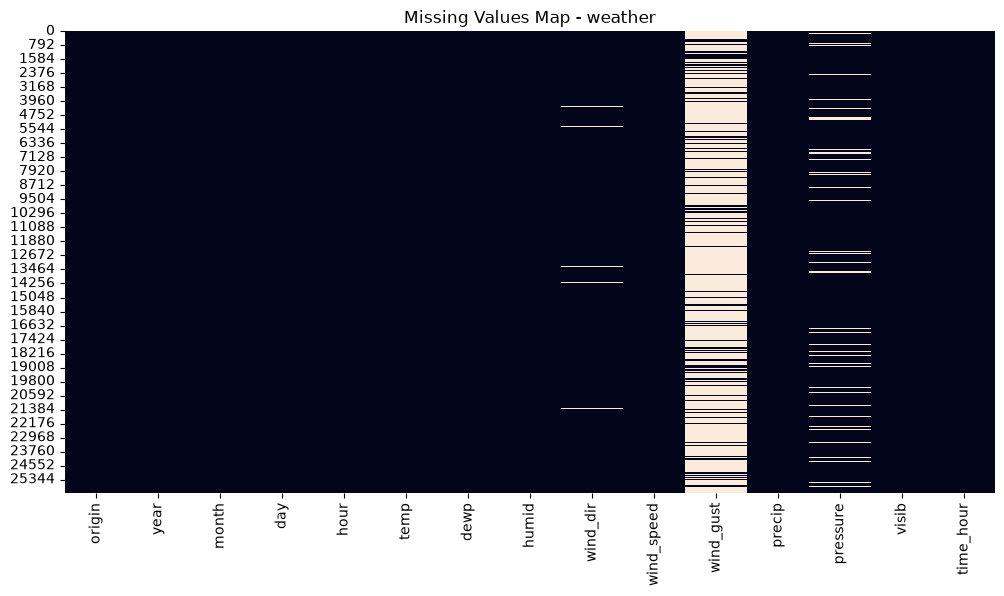

In [55]:
plt.figure(figsize=(12,6))
sns.heatmap(df4.isna(), cbar=False)
plt.title("Missing Values Map - weather")
plt.show()

### Q2. Are there any duplicates in this data?

In [56]:
print("Duplicate rows:", df4.duplicated().sum())

Duplicate rows: 0


### Q3. Create a correlation matrix of MISSING Weather variables? Explain.

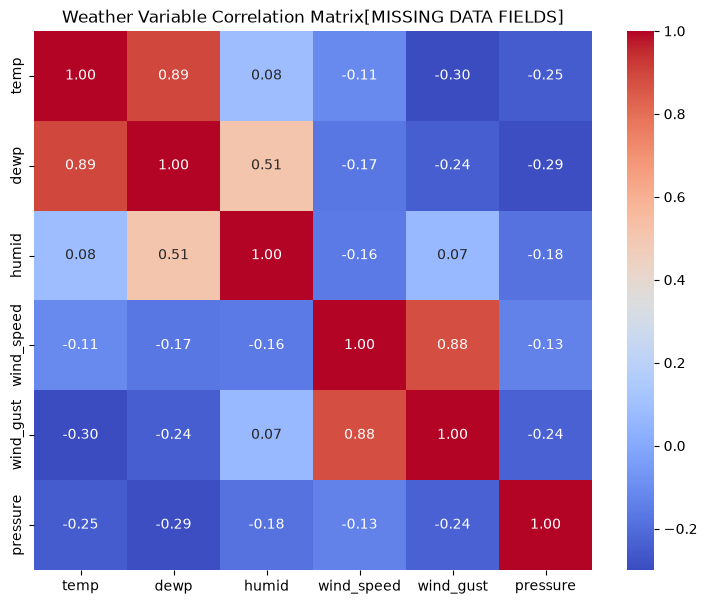

In [57]:
weather_cols=['temp', 'dewp', 'humid', 'wind_speed', 'wind_gust', 'pressure']

plt.figure(figsize=(9, 7))
sns.heatmap(df4[weather_cols].corr(), cmap='coolwarm',annot=True, fmt='.2f')
plt.title('Weather Variable Correlation Matrix[MISSING DATA FIELDS]')
plt.show()

### WEATHER DATA CORRELATION HEATMAP

** `Temperature(temp) and Dew Point(dewp)` : 0.89 | `STRONG POSITIVE`
Dew point and air temperature move together almost in lockstep - matches concept of basic atmospheric physics (dew point is mathematically bounded by temperature)

** `Wind Speed(wind_speed) and Wind Gust(wind_gust)`: 0.88 | `STRONG POSITIVE`
Higher sustained wind should bring higher gusts

** `Dew Point(dewp) and Humidity(humid)`: 0.51 | `MODERATE`

** `Wind Gust(wind_gust) and Pressure`: -0.24 (Negative) | `WEAK`
** `Temperature(temp) and Wind Gust(wind_gust)` : -0.30 (Negative) | `WEAK`
Validated the understanding that low-pressure systems (storms) tend to bring more of weather activity (in general)

** `Humidity(humid) and Wind Gust(wind_gust)` : 0.07 | `NO RELATION`

#### Quick snapshot of first 20 rows of data

In [58]:
display(df4.head(20))

,origin,year,month,day,hour,temp,dewp,humid,wind_dir,wind_speed,wind_gust,precip,pressure,visib,time_hour
0,EWR,2013,1,1,1,39.02,26.06,59.37,270.0,10.35702,NaN,0.0,1012.0,10.0,2013-01-01T06:00:00Z
1,EWR,2013,1,1,2,39.02,26.96,61.63,250.0,8.05546,NaN,0.0,1012.3,10.0,2013-01-01T07:00:00Z
2,EWR,2013,1,1,3,39.02,28.04,64.43,240.0,11.50780,NaN,0.0,1012.5,10.0,2013-01-01T08:00:00Z
3,EWR,2013,1,1,4,39.92,28.04,62.21,250.0,12.65858,NaN,0.0,1012.2,10.0,2013-01-01T09:00:00Z
4,EWR,2013,1,1,5,39.02,28.04,64.43,260.0,12.65858,NaN,0.0,1011.9,10.0,2013-01-01T10:00:00Z
5,EWR,2013,1,1,6,37.94,28.04,67.21,240.0,11.50780,NaN,0.0,1012.4,10.0,2013-01-01T11:00:00Z
6,EWR,2013,1,1,7,39.02,28.04,64.43,240.0,14.96014,NaN,0.0,1012.2,10.0,2013-01-01T12:00:00Z
7,EWR,2013,1,1,8,39.92,28.04,62.21,250.0,10.35702,NaN,0.0,1012.2,10.0,2013-01-01T13:00:00Z
8,EWR,2013,1,1,9,39.92,28.04,62.21,260.0,14.96014,NaN,0.0,1012.7,10.0,2013-01-01T14:00:00Z
9,EWR,2013,1,1,10,41.00,28.04,59.65,260.0,13.80936,NaN,0.0,1012.4,10.0,2013-01-01T15:00:00Z


### **5.3** Feature Engineering

In [59]:
df4_clean = df4.copy()

#FE - 1. clean time_hour column
date_cols = ["time_hour"]
for col in date_cols:
    df4_clean[col] = pd.to_datetime(df4_clean[col], errors="coerce")

display(df4_clean.head(5))

print("Cleaned shape:", df4_clean.shape)

,origin,year,month,day,hour,temp,dewp,humid,wind_dir,wind_speed,wind_gust,precip,pressure,visib,time_hour
0,EWR,2013,1,1,1,39.02,26.06,59.37,270.0,10.35702,NaN,0.0,1012.0,10.0,2013-01-01 06:00:00+00:00
1,EWR,2013,1,1,2,39.02,26.96,61.63,250.0,8.05546,NaN,0.0,1012.3,10.0,2013-01-01 07:00:00+00:00
2,EWR,2013,1,1,3,39.02,28.04,64.43,240.0,11.50780,NaN,0.0,1012.5,10.0,2013-01-01 08:00:00+00:00
3,EWR,2013,1,1,4,39.92,28.04,62.21,250.0,12.65858,NaN,0.0,1012.2,10.0,2013-01-01 09:00:00+00:00
4,EWR,2013,1,1,5,39.02,28.04,64.43,260.0,12.65858,NaN,0.0,1011.9,10.0,2013-01-01 10:00:00+00:00


Cleaned shape: (26115, 15)


In [60]:
missing = pd.DataFrame({
    "missing_count": df4_clean.isna().sum(),
    "missing_percentage": (df4_clean.isna().sum()/len(df4)*100).round(2)
}).sort_values("missing_count", ascending=False)

missing.head(15)

,missing_count,missing_percentage
wind_gust,20778,79.56
pressure,2729,10.45
wind_dir,460,1.76
wind_speed,4,0.02
dewp,1,0.00
temp,1,0.00
humid,1,0.00
day,0,0.00
hour,0,0.00
year,0,0.00


### Q4. Why Wind Gust values are missing in such huge numbers? How do we handle it?

In [61]:
print(df4_clean.loc[df4_clean['wind_gust'].isna(),'wind_speed'].describe())
print(df4_clean.loc[df4_clean['wind_gust'].notna(),'wind_speed'].describe())

count    20774.000000
mean         8.846337
std          8.451830
min          0.000000
25%          5.753900
50%          8.055460
75%         11.507800
max       1048.360580
Name: wind_speed, dtype: float64
count    5337.000000
mean       17.022358
std         5.051856
min         3.452340
25%        13.809360
50%        16.110920
75%        19.563260
max        42.578860
Name: wind_speed, dtype: float64


#### Takeaway
**Wind_gust field values are missing mostly when wind_speed is low.**
 
    We can validate this by looking at the  Median value(50%) which is 8.06  for ISNA group median value and 
    NOTNA group Median value(50%) 16.11.
    Since large amounts of WIND GUST data is missing, imputation is not possible since this is MISSING NOT AT RANDOM scenario.

**We will be dropping this column and create a separate dataframe at the end of this section.**

### Q5. What's the wind speed range/details for the year 2013?

In [62]:
print(df4_clean["wind_speed"].describe().round(2))

count    26111.00
mean        10.52
std          8.54
min          0.00
25%          6.90
50%         10.36
75%         13.81
max       1048.36
Name: wind_speed, dtype: float64


### Q6. Is there a data outlier in wind_speed, and how should it be handled?

In [63]:
# data issue identified - maximum wind speed is >1000 for isna group

df4_clean['wind_speed'].sort_values(ascending=False).head(10)

1009     1048.36058
724        42.57886
9425       42.57886
18131      40.27730
722        40.27730
726        39.12652
10249      37.97574
9428       36.82496
16536      36.82496
9424       36.82496
Name: wind_speed, dtype: float64

In [64]:
df4_clean.loc[[1009]]

,origin,year,month,day,hour,temp,dewp,humid,wind_dir,wind_speed,wind_gust,precip,pressure,visib,time_hour
1009,EWR,2013,2,12,3,39.02,26.96,61.63,260.0,1048.36058,NaN,0.0,1008.3,10.0,2013-02-12 08:00:00+00:00


#### Response: 
**Yes — one reading of 1,048 mph** - which is physically impossible.

**We will be dropping this value** and treating it as a missing rather than a real value.

#### Data cleaning/ FE continued ---

In [65]:
#2. clean wind speed outlier value
weather_fe = df4_clean.drop(df4_clean[df4_clean["wind_speed"] > 1000].index)

#3. dropping wind gust column altogether 
weather_fe = weather_fe.drop(columns=["wind_gust"])


### Q7. Excluding that outlier, what's the realistic wind speed range for the year?

In [66]:
print(weather_fe["wind_speed"].describe().round(2))

count    26110.00
mean        10.48
std          5.63
min          0.00
25%          6.90
50%         10.36
75%         13.81
max         42.58
Name: wind_speed, dtype: float64


### Q8. Explain wind speed distribution by airport ?

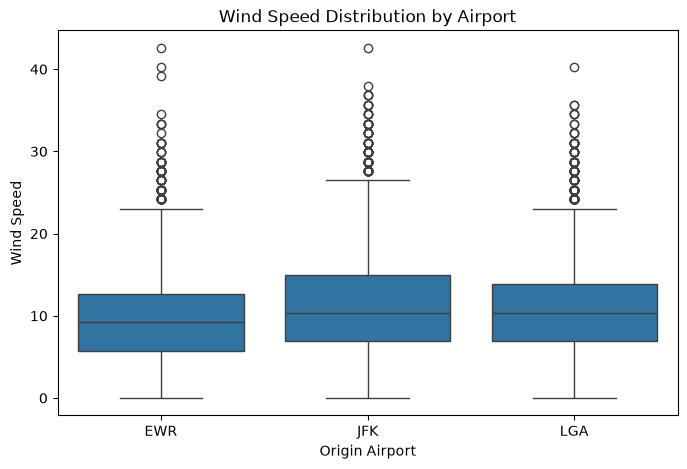

In [67]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=weather_fe, x='origin', y='wind_speed')
plt.title('Wind Speed Distribution by Airport')
plt.xlabel('Origin Airport')
plt.ylabel('Wind Speed')

plt.show()

#### Response:
**JFK and LGA run consistently windier than Newark.**
JFK has the highest median windspeed (~10.5 mph) and the widest interquartile range (~7-15 mph), 
LGA close behind (median ~10.5 mph, IQR ~7-14 mph). 
EWR is lowest on both counts (median ~9 mph, IQR ~5.5-12.5mph). 

All three airports show a long tail of outlier readings reaching into the high 30s/low 40s mph — expected for real wind gusts during storms, and that  single largest outlier 1,048 mph no longer appears here anymore post cleaning.

### Q9. Which NYC origin airport recorded the most adverse-weather?

#### Response:
JFK had the highest rate of "adverse weather" of the three airports - basis boxplot analysis above.

### Q10. What's the Pressure range/details for the year 2013?

In [68]:
print(weather_fe["pressure"].describe().round(2))

count    23385.00
mean      1017.90
std          7.42
min        983.80
25%       1012.90
50%       1017.60
75%       1023.00
max       1042.10
Name: pressure, dtype: float64


We know from our earlier assessment - for pressure, 2729 values is the missing count (~10%).

**WIND PRESSURE -  Pressure isn't MNAR like wind_gust.
**There is no reason pressure would be missing/zero - it's most likely a sensor/reporting issue

In [69]:
## Review of first 15 values of sorting on Pressure values

weather_fe = weather_fe.sort_values(['origin', 'time_hour']).reset_index(drop=True) # doesn't work without drop=true
display(weather_fe.head(15))


,origin,year,month,day,hour,temp,dewp,humid,wind_dir,wind_speed,precip,pressure,visib,time_hour
0,EWR,2013,1,1,1,39.02,26.06,59.37,270.0,10.35702,0.0,1012.0,10.0,2013-01-01 06:00:00+00:00
1,EWR,2013,1,1,2,39.02,26.96,61.63,250.0,8.05546,0.0,1012.3,10.0,2013-01-01 07:00:00+00:00
2,EWR,2013,1,1,3,39.02,28.04,64.43,240.0,11.50780,0.0,1012.5,10.0,2013-01-01 08:00:00+00:00
3,EWR,2013,1,1,4,39.92,28.04,62.21,250.0,12.65858,0.0,1012.2,10.0,2013-01-01 09:00:00+00:00
4,EWR,2013,1,1,5,39.02,28.04,64.43,260.0,12.65858,0.0,1011.9,10.0,2013-01-01 10:00:00+00:00
5,EWR,2013,1,1,6,37.94,28.04,67.21,240.0,11.50780,0.0,1012.4,10.0,2013-01-01 11:00:00+00:00
6,EWR,2013,1,1,7,39.02,28.04,64.43,240.0,14.96014,0.0,1012.2,10.0,2013-01-01 12:00:00+00:00
7,EWR,2013,1,1,8,39.92,28.04,62.21,250.0,10.35702,0.0,1012.2,10.0,2013-01-01 13:00:00+00:00
8,EWR,2013,1,1,9,39.92,28.04,62.21,260.0,14.96014,0.0,1012.7,10.0,2013-01-01 14:00:00+00:00
9,EWR,2013,1,1,10,41.00,28.04,59.65,260.0,13.80936,0.0,1012.4,10.0,2013-01-01 15:00:00+00:00


### Q11. How many pressure readings are missing, and is it concentrated in particular months?

In [70]:
weather_fe["pressure"].isnull().groupby(weather_fe["month"]).sum()

month
1     249
2     262
3     207
4     187
5     302
6     289
7     264
8     166
9     127
10    177
11    177
12    322
Name: pressure, dtype: int64

#### Response:
Of 2,729 missing overall, **missing spread fairly evenly across all 12 months** (roughly 130-320
per month) rather than concentrated in one period — consistent with an intermittent sensor
issue rather than a systematic seasonal gap.

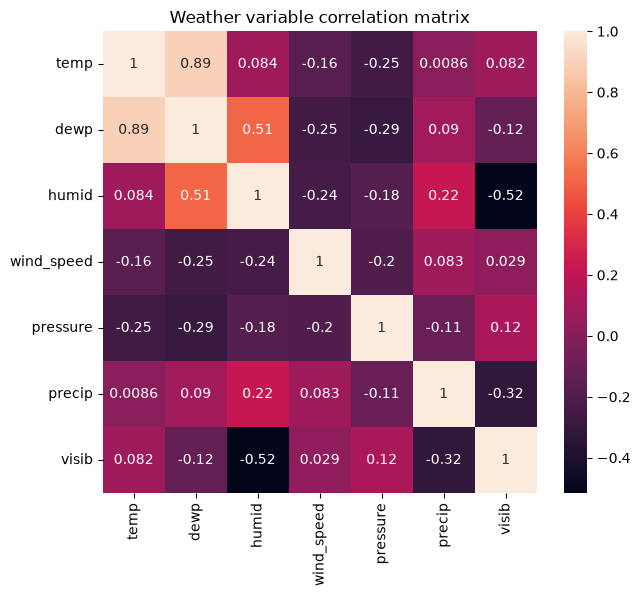

In [71]:
cols = ["temp", "dewp", "humid", "wind_speed", "pressure", "precip", "visib"]  # wind_dir excluded — circular, not linear
corr_matrix = weather_fe[cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr_matrix, annot=True)
ax.set_title("Weather variable correlation matrix")
plt.show()

#### Takeaway:
** `temp and dewp` : Very Strong Relationship | 0.89
    unchanged from the earlier 6-variable version. 

Adding `precip` and `visib` surfaces one genuinely useful new signal:

**`humid and visib` : Moderate relationship | -0.52 
a real moderate relationship — humid air is meaningfully associated with reduced visibility, which makes physical sense (fog, haze)

** `precip and visib` : Moderately negative | -0.32
This is consistent with rain reducing visibility.

Every other correlation involving `precip` stays weak (0.01 to 0.22)

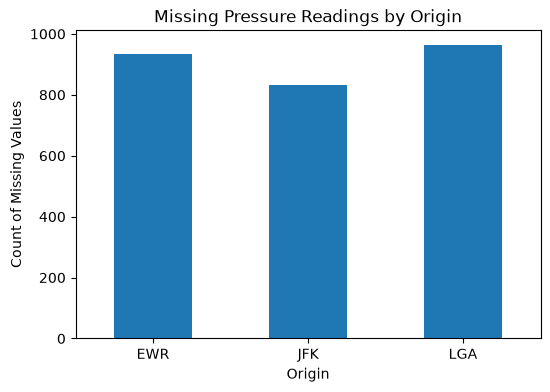

In [72]:
missing_by_origin = df4_clean[df4_clean['pressure'].isna()].groupby('origin').size()

plt.figure(figsize=(6, 4))
missing_by_origin.plot(kind='bar')
plt.title('Missing Pressure Readings by Origin')
plt.xlabel('Origin')
plt.ylabel('Count of Missing Values')
plt.xticks(rotation=0)

plt.show()

In [73]:
df4_clean_pressure = df4_clean.copy()
df4_clean_pressure['pressure'] = df4_clean.groupby(['origin', 'year', 'month', 'day'])['pressure'].transform(
    lambda x: x.fillna(x.median())
)

display(df4_clean_pressure['pressure'].isna().sum())

np.int64(0)

### Q12. Can the missing pressure readings be filled in?

Pressure is missing at random (spread across all months and airports, consistent with an intermittent sensor issue), so a same-day median per airport is a reasonable fill. This is kept in a separate dataframe (`df4_clean_pressure`) so the main cleaned data stays untouched. Not used in the later parts.